Homework 3, problem 4, part c

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [16]:
def qif_gap_junctions(t, y, epsilon):
    v1, v2 = y
    dv1 = 1 + v1**2 + epsilon * (v2 - v1)
    dv2 = 1 + v2**2 + epsilon * (v1 - v2)
    return [dv1, dv2]

In [17]:
# parameters
L = 200.0
epsilon = 0.02
phi_0 = 0.4

t2_init = phi_0 * np.pi
v1_init = -L  # neuron 1 at reset
v2_init = -1.0 / np.tan(t2_init)  # neuron 2 lagging

t_span = [0, 150]
y_init = [v1_init, v2_init]

def spike_neuron1(t, y, epsilon):
    return y[0] - L

spike_neuron1.terminal = True
spike_neuron1.direction = 1


def spike_neuron2(t, y, epsilon):
    return y[1] - L

spike_neuron2.terminal = True
spike_neuron2.direction = 1

In [18]:
t_curr = 0
y_curr = y_init
t1_spikes = []
t2_spikes = []

while t_curr < t_span[1]:

    sol = solve_ivp(
        qif_gap_junctions,
        [t_curr, t_span[1]],
        y_curr,
        events=[spike_neuron1, spike_neuron2],
        args=(epsilon,),
        rtol=1e-9,
        atol=1e-9
    )

    t_curr = sol.t[-1]
    y_curr = sol.y[:, -1]

    if sol.status == 1:

        if len(sol.t_events[0]) > 0:
            t1_spikes.append(sol.t_events[0][-1])
            y_curr[0] = -L

        if len(sol.t_events[1]) > 0:
            t2_spikes.append(sol.t_events[1][-1])
            y_curr[1] = -L

    else:
        break


# Calculate phase differences
phi_k = []

iterations = min(len(t1_spikes) - 1, len(t2_spikes))

for k in range(iterations):
    period = t1_spikes[k+1] - t1_spikes[k]
    lag = t2_spikes[k] - t1_spikes[k]
    phi_k.append(lag / period)

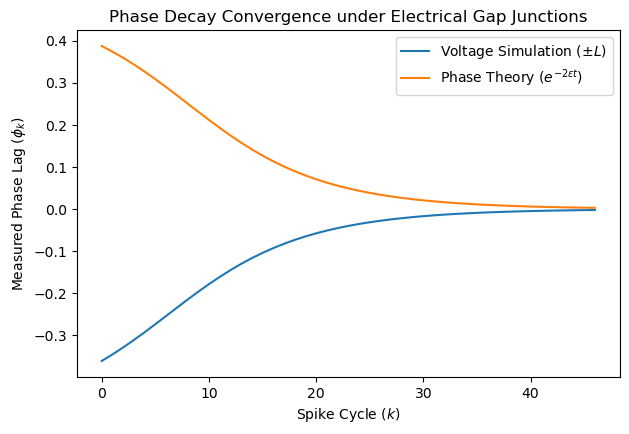

In [19]:
t_theory = np.array(t1_spikes[:iterations])
phi_theory = np.arctan(np.tan(np.pi * phi_0) * np.exp(-2 * epsilon * t_theory)) / np.pi

plt.figure(figsize=(7, 4.5))
plt.plot(range(iterations), phi_k, label='Voltage Simulation ($\pm L$)')
plt.plot(range(iterations), phi_theory, label='Phase Theory ($e^{-2\epsilon t}$)')
plt.xlabel('Spike Cycle ($k$)')
plt.ylabel('Measured Phase Lag ($\phi_k$)')
plt.title('Phase Decay Convergence under Electrical Gap Junctions')

plt.legend()
plt.show()
